# 2026-10-22 예측 모델 제작

**선택한 문제 : 문제 [1] 포켓몬 능력치(`Total`) 예측 (회귀)**

## 데이터 설명

포켓몬 **721마리**(1~6세대), **23개 컬럼**으로 이루어져 있습니다.

| 컬럼명 | 설명 |
| --- | --- |
| `Number` | 포켓몬 도감 번호 (고유 ID) |
| `Name` | 포켓몬 이름 |
| `Type_1` | 주 타입 |
| `Type_2` | 보조 타입 (없으면 결측) |
| `Total` | 여섯 능력치(`HP`, `Attack`, `Defense`, `Sp_Atk`, `Sp_Def`, `Speed`)의 **합** |
| `HP` | 체력 |
| `Attack` | 물리 공격 |
| `Defense` | 물리 방어 |
| `Sp_Atk` | 특수 공격 |
| `Sp_Def` | 특수 방어 |
| `Speed` | 스피드 |
| `Generation` | 등장 세대 (1~6) |
| `isLegendary` | 전설 포켓몬 여부 (True/False) |
| `Color` | 도감상 색상 |
| `hasGender` | 성별 구분이 있는지 여부 |
| `Pr_Male` | 수컷일 확률 (암컷 확률은 `1 - Pr_Male`) |
| `Egg_Group_1` | 첫 번째 알 그룹 |
| `Egg_Group_2` | 두 번째 알 그룹 (없으면 결측) |
| `hasMegaEvolution` | 메가진화 가능 여부 |
| `Height_m` | 키 (m) |
| `Weight_kg` | 몸무게 (kg) |
| `Catch_Rate` | 포획률 (높을수록 잡기 쉬움) |
| `Body_Style` | 도감상 몸 형태 |


💡 **공통 규칙**

- `Number`, `Name`은 식별용 값이므로 **feature로 사용하지 않습니다.**
- 학습/검증 데이터 분리는 `test_size=0.2`, `random_state=42`로 **고정**합니다.
- 모델을 만들 때도 `random_state=42`를 지정합니다.
- 컬럼명은 대소문자까지 정확히 입력하시오. (예: `Pr_Male`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _style import setup
from _ml import (load_pokemon, fill_missing, encode, SEED, TEST_SIZE, STATS,
                 REG_TARGET, REG_FEATURES, REG_NUM_COLS)

setup()     # 한글 폰트, 마이너스 기호 설정
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 25)

print("준비 완료")

준비 완료


---
## 해결 과제 (공통)

### 1. `pandas`를 사용하여 `pokemon_alopez247.csv` 파일 데이터를 불러와 **`DataFrame`** 으로 저장하시오.

In [2]:
df = load_pokemon()

print("저장 완료")
print(f"형태(행/열) : {df.shape} / {df.shape[0]} 행 {df.shape[1]} 열")

저장 완료
형태(행/열) : (721, 23) / 721 행 23 열


### 2. 저장된 데이터에서 상위 5개 행을 출력하시오.

In [3]:
df.head()

,Number,Name,Type_1,Type_2,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Generation,isLegendary,Color,hasGender,Pr_Male,Egg_Group_1,Egg_Group_2,hasMegaEvolution,Height_m,Weight_kg,Catch_Rate,Body_Style
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False,Green,True,0.875,Monster,Grass,False,0.71,6.9,45,quadruped
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False,Green,True,0.875,Monster,Grass,False,0.99,13.0,45,quadruped
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False,Green,True,0.875,Monster,Grass,True,2.01,100.0,45,quadruped
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False,Red,True,0.875,Monster,Dragon,False,0.61,8.5,45,bipedal_tailed
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,1,False,Red,True,0.875,Monster,Dragon,False,1.09,19.0,45,bipedal_tailed


### 3. 각 열의 이름, 결측치 여부, 데이터 타입(`dtype`)을 한 번에 확인하시오.

<aside>

`df.info()`를 실행한 후, 출력 결과를 바탕으로 다음을 기술하시오.

- 결측치가 존재하는 열과 결측 개수
- 각 열의 결측이 **무엇을 의미하는지** (위 데이터 설명 참고)
</aside>

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Number            721 non-null    int64  
 1   Name              721 non-null    str    
 2   Type_1            721 non-null    str    
 3   Type_2            350 non-null    str    
 4   Total             721 non-null    int64  
 5   HP                721 non-null    int64  
 6   Attack            721 non-null    int64  
 7   Defense           721 non-null    int64  
 8   Sp_Atk            721 non-null    int64  
 9   Sp_Def            721 non-null    int64  
 10  Speed             721 non-null    int64  
 11  Generation        721 non-null    int64  
 12  isLegendary       721 non-null    bool   
 13  Color             721 non-null    str    
 14  hasGender         721 non-null    bool   
 15  Pr_Male           644 non-null    float64
 16  Egg_Group_1       721 non-null    str    
 17  Egg_Grou

In [5]:
# 결측이 있는 열만 골라서 개수, 비율 출력 (isna().sum() : 열별 결측 개수)
na = df.isna().sum()

print(f"{'열':<14}{'결측 수':>8}{'비율(%)':>10}")
print("-" * 34)

for col in df.columns:
    if na[col] > 0:
        print(f"{col:<14}{na[col]:>8}{na[col] / len(df) * 100:>10.2f}")

print()
# Pr_Male 이 결측인 포켓몬의 hasGender 값 확인 -> 전부 False 이면 "성별 없음" 이 결측의 의미
print("[Pr_Male 결측 행의 hasGender]")
print(df.loc[df["Pr_Male"].isna(), "hasGender"].value_counts())

열                 결측 수     비율(%)
----------------------------------
Type_2             371     51.46
Pr_Male             77     10.68
Egg_Group_2        530     73.51

[Pr_Male 결측 행의 hasGender]
hasGender
False    77
Name: count, dtype: int64


**결측치가 존재하는 열과 결측 개수, 각 열의 결측이 무엇을 의미하는지?**

|열|결측 개수|무엇을 의미?|
|:--:|:--:|:--:|
|`Type_2`|371|보조 타입이 **없는** 단일 타입 포켓몬 (잘못 빠진 값 X)|
|`Egg_Group_2`|530|두 번째 알 그룹이 **없는** 포켓몬|
|`Pr_Male`|77|**성별이 없는** 포켓몬 (77마리 모두 `hasGender=False`) -> 수컷 확률 자체를 정의할 수 없음|

> 세 열 모두 "값을 몰라서 비어있는 것" 이 아니라 **"해당 사항 없음"** 이라는 정보를 담고 있음\
> -> 행을 삭제(`dropna`)하면 그 정보가 사라지므로 **대치** 로 처리

### 4. 결측치를 처리하시오.

- 처리 방식은 자유롭게 선택해도 됩니다. (예: `fillna()`로 `'None'` 또는 특정 숫자 채우기)
- **왜 그렇게 처리했는지 한 줄로 기술**하시오.
- 처리 후 전체 결측치 개수가 0인지 확인하시오.

In [6]:
# fill_missing()
#   * Type_2, Egg_Group_2 -> fillna("None")  : "없음" 을 하나의 범주로
#   * Pr_Male             -> fillna(-1)      : 0 은 "전부 암컷" 이라는 뜻이라 확률 범위(0~1) 밖의 값 사용
print(f"처리 전 전체 결측 : {df.isna().sum().sum()} 개")

df = fill_missing(df)

print(f"처리 후 전체 결측 : {df.isna().sum().sum()} 개")
print()
print(f"Type_2 = 'None'      : {(df['Type_2'] == 'None').sum()} 개")
print(f"Egg_Group_2 = 'None' : {(df['Egg_Group_2'] == 'None').sum()} 개")
print(f"Pr_Male = -1         : {(df['Pr_Male'] == -1).sum()} 개")

처리 전 전체 결측 : 978 개
처리 후 전체 결측 : 0 개

Type_2 = 'None'      : 371 개
Egg_Group_2 = 'None' : 530 개
Pr_Male = -1         : 77 개


**결측치 처리 방법**\
`Type_2`·`Egg_Group_2` 는 `'None'`,\
`Pr_Male` 은 `-1` 로 채움\
-> 결측이 "없음/성별 없음" 이라는 **의미 있는 정보**라서, 삭제하지 않고 별도의 값으로 남겨 모델이 구분하게 함

### 5. 전설 포켓몬(`isLegendary`=`True`)과 일반 포켓몬이 각각 몇 마리인지, 전설 포켓몬의 비율(%)은 얼마인지 계산하시오.

In [7]:
cnt = df["isLegendary"].value_counts()

n_legend = cnt.loc[True]
n_normal = cnt.loc[False]

print(f"일반 포켓몬         : {n_normal} 마리")
print(f"전설 포켓몬         : {n_legend} 마리")
print(f"전설 포켓몬 비율    : {n_legend / len(df) * 100:.2f} %")

일반 포켓몬         : 675 마리
전설 포켓몬         : 46 마리
전설 포켓몬 비율    : 6.38 %


---
## 해결 과제 (선택)

> 아래 **문제 [1]** 또는 **문제 [2]** 중 **하나만 선택**하여 풀이하시오.

## 문제 [1] 포켓몬 능력치(`Total`) 예측 (회귀)

능력치 이외의 정보(타입, 세대, 키, 몸무게 등)로 `Total`을 예측하는 회귀 모델을 만든다.

### [1-1] `Total`을 타깃(`y`)으로 하고, 사용할 feature(`X`)를 정하시오.

⚠️ **`Total`과 여섯 능력치(`HP`, `Attack`, `Defense`, `Sp_Atk`, `Sp_Def`, `Speed`)는 feature로 사용하지 않는다.**

`Total`은 여섯 능력치를 더한 값이다. 능력치를 feature에 넣으면 정답이 입력에 그대로 들어가는 것이므로(데이터 누수) 예측 모델이라고 할 수 없다.

---

**사용 가능한 컬럼:** `Type_1`, `Type_2`, `Generation`, `isLegendary`, `Color`, `hasGender`, `Pr_Male`, `Egg_Group_1`, `Egg_Group_2`, `hasMegaEvolution`, `Height_m`, `Weight_kg`, `Catch_Rate`, `Body_Style`

In [8]:
y = df[REG_TARGET]

print(f"타깃(y) : {REG_TARGET}")
print(f"사용한 피처 ({len(REG_FEATURES)} 개)")
for i, col in enumerate(REG_FEATURES, start=1):
    print(f"  {i:>2}. {col:<18} {str(df[col].dtype)}")

타깃(y) : Total
사용한 피처 (14 개)
   1. Type_1             str
   2. Type_2             str
   3. Generation         int64
   4. isLegendary        bool
   5. Color              str
   6. hasGender          bool
   7. Pr_Male            float64
   8. Egg_Group_1        str
   9. Egg_Group_2        str
  10. hasMegaEvolution   bool
  11. Height_m           float64
  12. Weight_kg          float64
  13. Catch_Rate         int64
  14. Body_Style         str


### [1-2] 범주형 컬럼을 숫자로 변환하시오.

- `pd.get_dummies()` 등을 사용해도 됩니다.
- 변환 후 `X`의 컬럼 개수를 출력하시오.

In [9]:
X = encode(df, REG_FEATURES)

print(f"변환 전 피처 수   : {len(REG_FEATURES)} 개")
print(f"변환 후 X 컬럼 수 : {X.shape[1]} 개")
print()
print(X.columns.tolist()[:12], "...")

변환 전 피처 수   : 14 개
변환 후 X 컬럼 수 : 98 개

['Generation', 'isLegendary', 'hasGender', 'Pr_Male', 'hasMegaEvolution', 'Height_m', 'Weight_kg', 'Catch_Rate', 'Type_1_Bug', 'Type_1_Dark', 'Type_1_Dragon', 'Type_1_Electric'] ...


### [1-3] 수치형 변수(`Generation`, `Height_m`, `Weight_kg`, `Catch_Rate`, `Pr_Male`)와 `Total`의 상관계수를 구하시오.

- `df[[...]].corr()['Total']` 형식으로 계산하시오.
- 상관계수 절댓값이 가장 큰 변수 3개를 기술하시오.

In [10]:
corr = df[REG_NUM_COLS + [REG_TARGET]].corr()[REG_TARGET]
corr = corr.drop(REG_TARGET)        # 자기 자신(Total = 1.0)은 제외

print("[Total 과의 상관계수]")
print(corr.round(2))
print()

# 절댓값이 큰 순서 -> 음수 부호를 떼고 포함하여 비교
top3 = np.abs(corr).sort_values(ascending=False).head(3)

print("[상관계수 절댓값 상위 3개]")
for col in top3.index:
    print(f"  {col:<12} {corr[col]:>6.2f}")

[Total 과의 상관계수]
Generation    0.09
Height_m      0.53
Weight_kg     0.54
Catch_Rate   -0.74
Pr_Male      -0.32
Name: Total, dtype: float64

[상관계수 절댓값 상위 3개]
  Catch_Rate    -0.74
  Weight_kg      0.54
  Height_m       0.53


**상관계수 절댓값이 가장 큰 변수 3개**

|순위|변수|상관계수|Total 과의 관계|
|:--:|:--:|:--:|:--:|
|1|`Catch_Rate`|-0.74|**포획률이 높을수록** Total이 **낮음**|
|2|`Weight_kg`|0.54|**무거울수록** Total이 **높은 편**|
|3|`Height_m`|0.53|**클수록** Total이 **높은 편**|

### [1-4] 학습 데이터와 검증 데이터를 분리하고, 각각의 크기(`shape`)를 출력하시오.

- `train_test_split(X, y, test_size=0.2, random_state=42)`

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,                   # 입력, 정답
    test_size=TEST_SIZE,    # 학습 8 : 검증 2
    random_state=SEED       # 재현성 (42 고정)
)

print(f"X_train : {X_train.shape}  /  y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}  /  y_test  : {y_test.shape}")

X_train : (576, 98)  /  y_train : (576,)
X_test  : (145, 98)  /  y_test  : (145,)


### [1-5] `LinearRegression` 모델을 학습시키고, 검증 데이터에 대한 **R²**와 **RMSE**를 계산하시오.

💡**평가 지표**

| 지표 | 의미 |
| --- | --- |
| R² | 모델이 값의 변동을 얼마나 설명하는지. 1에 가까울수록 좋음 |
| RMSE | 평균적으로 얼마나 빗나갔는지. `Total` 점수와 같은 단위이며 작을수록 좋음 |

- `r2_score`, `mean_squared_error` (RMSE는 제곱근을 취하여 계산, `root_mean_squared_error` 활용 가능)
- 참고: `Total`의 표준편차는 약 110이다. 평균값만 예측하면 RMSE가 약 110, R²가 0 근처이다.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# LinearRegression 은 무작위 요소가 없어서 random_state 옵션이 없음
lin = LinearRegression()

lin.fit(X_train, y_train)               # 학습
pred_lin = lin.predict(X_test)          # 예측

# R^2  : 평균으로 찍을 때 대비 얼마나 잘 설명하는지 (1 에 가까울수록 좋음)
r2_lin = r2_score(y_test, pred_lin)
# RMSE : MSE 의 제곱근 -> Total 과 같은 단위로 "평균적으로 몇 점 빗나갔는지"
rmse_lin = np.sqrt(mean_squared_error(y_test, pred_lin))

print("[LinearRegression]")
print(f"  R^2  (검증) : {r2_lin:.2f}")
print(f"  RMSE (검증) : {rmse_lin:.2f}")
print(f"  R^2  (학습) : {lin.score(X_train, y_train):.2f}   <- score() : 회귀 모델은 R^2 반환")

[LinearRegression]
  R^2  (검증) : 0.63
  RMSE (검증) : 66.95
  R^2  (학습) : 0.76   <- score() : 회귀 모델은 R^2 반환


### [1-6] `RandomForestRegressor` 모델을 학습시키고, 검증 데이터에 대한 **R²**와 **RMSE**를 계산하시오.

In [13]:
from sklearn.ensemble import RandomForestRegressor

# max_depth=6 : 트리 깊이 제한 (과적합 방지)
rf = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)

rf.fit(X_train, y_train)                # 학습
pred_rf = rf.predict(X_test)            # 예측

r2_rf = r2_score(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))

print("[RandomForestRegressor]")
print(f"  R^2  (검증) : {r2_rf:.2f}")
print(f"  RMSE (검증) : {rmse_rf:.2f}")
print(f"  R^2  (학습) : {rf.score(X_train, y_train):.2f}")

[RandomForestRegressor]
  R^2  (검증) : 0.78
  RMSE (검증) : 51.11
  R^2  (학습) : 0.89


### [1-7] 두 모델의 성능을 표로 정리하고, 성능 목표 달성 여부를 확인하시오.

💡**성능 목표**

| 모델 | R² | RMSE |
| --- | --- | --- |
| `LinearRegression` | 0.60 이상 | 70 이하 |
| `RandomForestRegressor` | 0.75 이상 | 55 이하 |

- 두 모델 중 어느 쪽이 더 잘 맞았는지, 그 이유는 무엇일지 기술하시오.

In [14]:
# 성능 목표 : 모델명 -> (R^2 최소값, RMSE 최대값)
GOAL = {
    "LinearRegression": (0.60, 70),
    "RandomForestRegressor": (0.75, 55)
}

rows = []

for name, r2, rmse in [("LinearRegression", r2_lin, rmse_lin),
                       ("RandomForestRegressor", r2_rf, rmse_rf)]:
    goal_r2, goal_rmse = GOAL[name]
    ok = (r2 >= goal_r2) and (rmse <= goal_rmse)    # 두 조건 모두 만족해야 달성

    rows.append({
        "모델": name,
        "R^2": round(r2, 2),
        "목표 R^2": f"{goal_r2:.2f} 이상",
        "RMSE": round(rmse, 2),
        "목표 RMSE": f"{goal_rmse} 이하",
        "목표 달성": "O" if ok else "X"
    })

result = pd.DataFrame(rows)
print(result.to_string(index=False))

                   모델  R^2  목표 R^2  RMSE 목표 RMSE 목표 달성
     LinearRegression 0.63 0.60 이상 66.95   70 이하     O
RandomForestRegressor 0.78 0.75 이상 51.11   55 이하     O


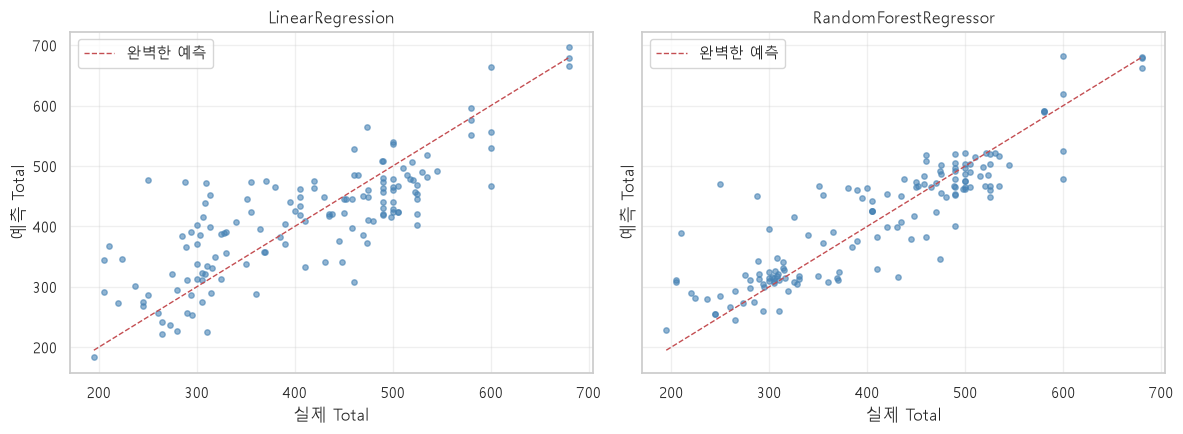

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, name, pred in zip(axes, ["LinearRegression", "RandomForestRegressor"], [pred_lin, pred_rf]):
    ax.scatter(y_test, pred, s=15, alpha=0.6, color="steelblue")

    lo, hi = y_test.min(), y_test.max()
    ax.plot([lo, hi], [lo, hi], "r--", lw=1, label="완벽한 예측")

    ax.set_xlabel("실제 Total")
    ax.set_ylabel("예측 Total")
    ax.set_title(f"{name}")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

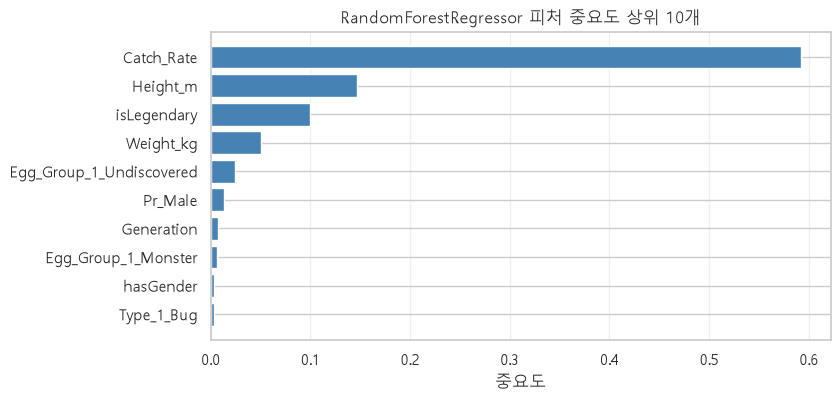

Catch_Rate                  0.59
Height_m                    0.15
isLegendary                 0.10
Weight_kg                   0.05
Egg_Group_1_Undiscovered    0.02
dtype: float64


In [16]:
# 모델이 판단할 때 어떤 피처를 많이 사용했는지 (인과관계 X)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
top10 = imp.tail(10)        # 오름차순 정렬의 마지막 10개 = 상위 10개

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(top10.index, top10.values, color="steelblue")

ax.set_xlabel("중요도")
ax.set_title("RandomForestRegressor 피처 중요도 상위 10개")
ax.grid(alpha=0.3, axis="x")

plt.show()

print(imp.sort_values(ascending=False).head(5).round(2))

**두 모델 중 어느 쪽이 더 잘 맞았는지, 그 이유는 무엇인가?**

**`RandomForestRegressor` 가 더 잘 맞음**\
(R^2 0.78 vs 0.63 / RMSE 51.11 vs 66.95 -> 평균 약 16점 덜 빗나감)\
두 모델 모두 성능 목표는 달성

**잘 맞은 이유**
1. **관계가 직선이 아님 (비선형)**
    - 가장 중요한 `Catch_Rate` 의 평균 Total 
        3 -> 604 / 45 -> 456 / 190 -> 312 / 255 -> 278
    - 3 ~ 45 구간에서는 급하게 떨어지고, 45 이후로는 완만하게 떨어지는 **곡선 형태**
    - 선형 회귀는 **직선 하나로만 표현** 가능
    - 트리는 "Catch_Rate <= 45 ?" 처럼 구간을 나눠서 **계단식으로** 따라감

2. **피처 조합(상호작용)을 반영**
    - 트리는 "포획률 낮음 -> 그 안에서 키가 큼 -> ..." 처럼 **조건을 이어서 나눔**
    - 선형 회귀는 각 피처의 효과를 **단순히 더하기만 함**

3. **선형 회귀는 이상치/희소 열에 약함**
    - 몸무게 최댓값 950kg (평균 약 57kg) 같은 이상치가 직선을 끌고 감
    - 원핫 98개 열 중 대부분이 거의 0인 열 -> 576행으로 가중치를 안정적으로 정하기 어려움\

> 피처 중요도에서도 `Catch_Rate` 가 0.59 로 압도적 -> 모델이 "포획률" 을 기준으로 가장 많이 나눴음

---

### 알게 된 점 / 어려웠던 점
- 결측치는 잘못 빠져 비어 있는 값만이 아닌, 'Type_2' 처럼 의도적으로 없는 존재를 나타낼 수도 있음
    - 도메인 지식을 통한 결측의 의미를 제대로 파악해야함
    
- 점수가 너무 좋으면 누수를 먼저 의심해야함
    - 능력치를 피처에 포함시키면 R^2 가 1.0이 되어버림

- 모델 비교가 왜 이런 결과가 나왔는지를 도메인 지식을 포함하여 알아야 파악할 수 있어서 해석하는데 어려움이 있었음